In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8   

In [2]:
# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Statistical summary
print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (1599, 12)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Missing Values:
fixed acidity           0
volatile acidity        0
citric ac

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


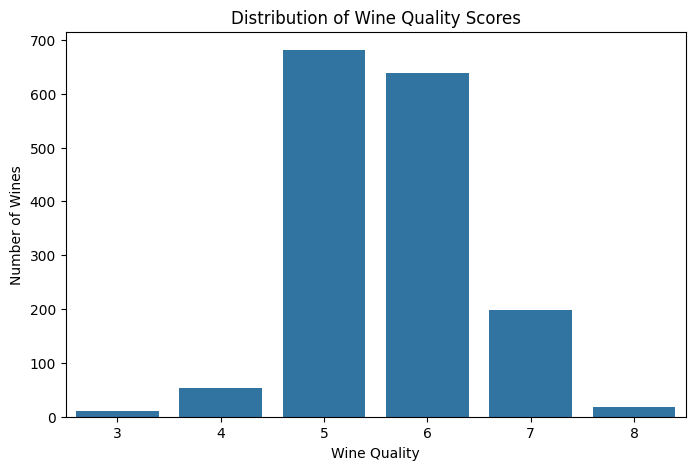

In [3]:
# Count each wine quality score
print(df["quality"].value_counts().sort_index())

# Visualize quality distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="quality")
plt.title("Distribution of Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")
plt.show()

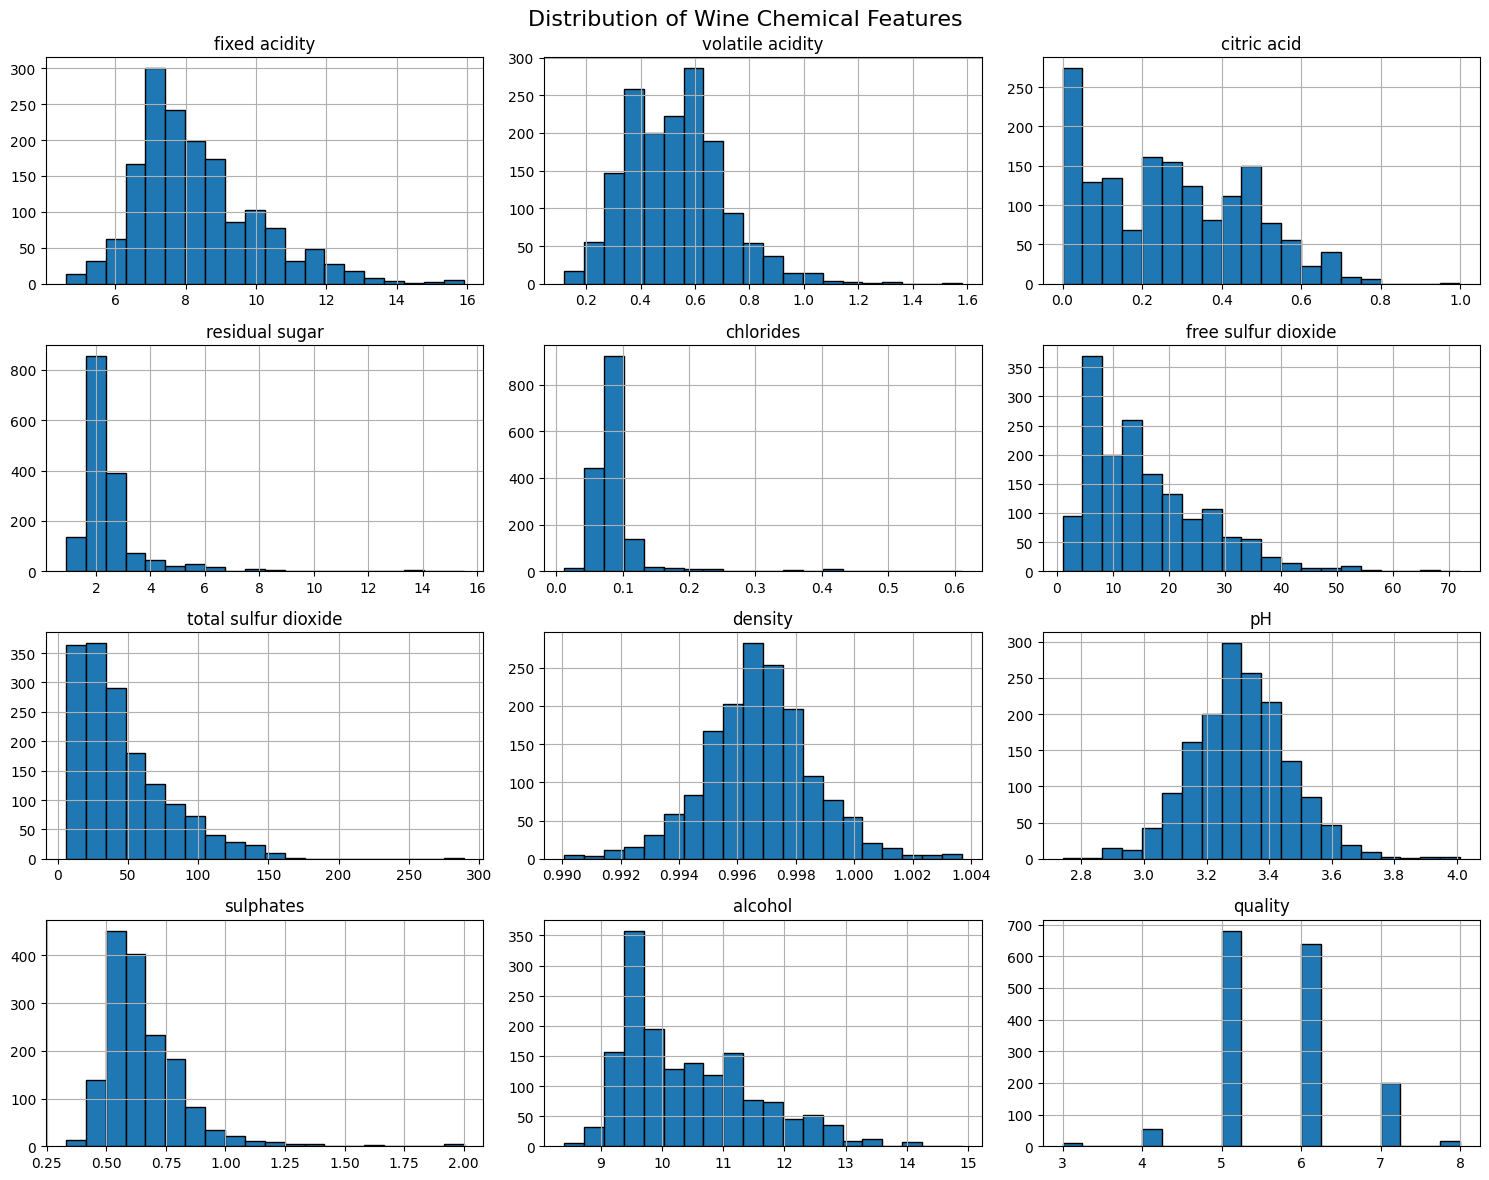

In [4]:
# Distribution of all chemical features
df.hist(figsize=(15, 12), bins=20, edgecolor="black")

plt.suptitle("Distribution of Wine Chemical Features", fontsize=16)
plt.tight_layout()
plt.show()

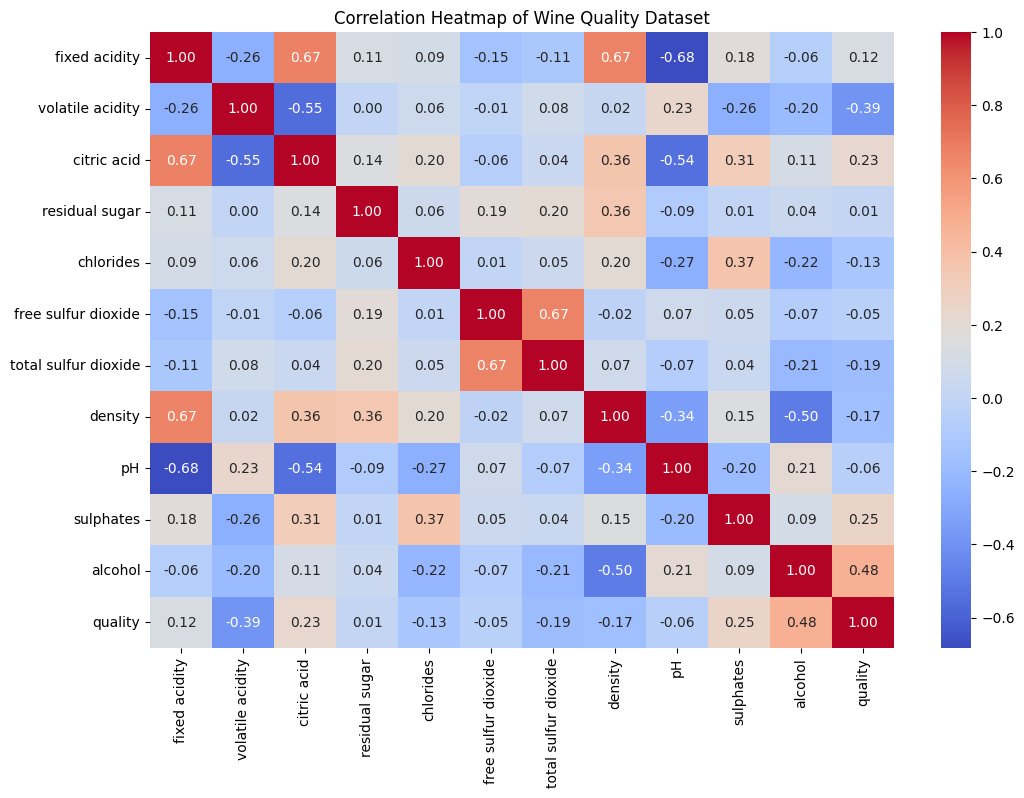

In [5]:
plt.figure(figsize=(12, 8))

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Wine Quality Dataset")
plt.show()

In [6]:
# Convert quality scores into 3 categories
def categorize_quality(quality):
    if quality <= 5:
        return "Low"
    elif quality == 6:
        return "Medium"
    else:
        return "High"

df["quality_category"] = df["quality"].apply(categorize_quality)

# Display category counts
print("Wine Quality Categories:")
print(df["quality_category"].value_counts())

# Display first five rows
print("\nUpdated Dataset:")
print(df[["quality", "quality_category"]].head())

Wine Quality Categories:
quality_category
Low       744
Medium    638
High      217
Name: count, dtype: int64

Updated Dataset:
   quality quality_category
0        5              Low
1        5              Low
2        5              Low
3        6           Medium
4        5              Low


In [7]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(["quality", "quality_category"], axis=1)
y = df["quality_category"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining category distribution:")
print(y_train.value_counts())

Training data shape: (1279, 11)
Testing data shape: (320, 11)

Training category distribution:
quality_category
Low       595
Medium    510
High      174
Name: count, dtype: int64


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest Model trained successfully!")
print("Predictions:", rf_predictions[:10])

Random Forest Model trained successfully!
Predictions: ['Low' 'Low' 'Medium' 'Low' 'Medium' 'Low' 'Medium' 'Medium' 'Medium'
 'High']


In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC

# SGD Classifier
sgd_model = make_pipeline(
    StandardScaler(),
    SGDClassifier(random_state=42, max_iter=1000, tol=1e-3)
)

sgd_model.fit(X_train, y_train)
sgd_predictions = sgd_model.predict(X_test)

# Support Vector Classifier
svc_model = make_pipeline(
    StandardScaler(),
    SVC()
)

svc_model.fit(X_train, y_train)
svc_predictions = svc_model.predict(X_test)

print("SGD Model trained successfully!")
print("SVC Model trained successfully!")

SGD Model trained successfully!
SVC Model trained successfully!


In [10]:
from sklearn.metrics import accuracy_score, classification_report

# Evaluate Random Forest
print("RANDOM FOREST")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print(classification_report(y_test, rf_predictions))

# Evaluate SGD
print("\nSGD CLASSIFIER")
print("Accuracy:", accuracy_score(y_test, sgd_predictions))
print(classification_report(y_test, sgd_predictions))

# Evaluate SVC
print("\nSUPPORT VECTOR CLASSIFIER")
print("Accuracy:", accuracy_score(y_test, svc_predictions))
print(classification_report(y_test, svc_predictions))

RANDOM FOREST
Accuracy: 0.753125
              precision    recall  f1-score   support

        High       0.71      0.58      0.64        43
         Low       0.80      0.83      0.82       149
      Medium       0.71      0.72      0.71       128

    accuracy                           0.75       320
   macro avg       0.74      0.71      0.72       320
weighted avg       0.75      0.75      0.75       320


SGD CLASSIFIER
Accuracy: 0.596875
              precision    recall  f1-score   support

        High       0.39      0.21      0.27        43
         Low       0.67      0.82      0.73       149
      Medium       0.53      0.47      0.50       128

    accuracy                           0.60       320
   macro avg       0.53      0.50      0.50       320
weighted avg       0.57      0.60      0.58       320


SUPPORT VECTOR CLASSIFIER
Accuracy: 0.665625
              precision    recall  f1-score   support

        High       0.65      0.40      0.49        43
         Low   

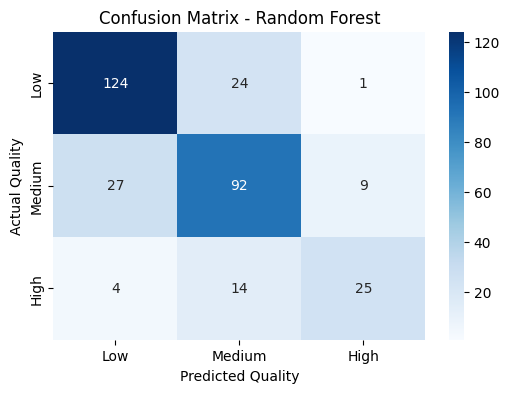

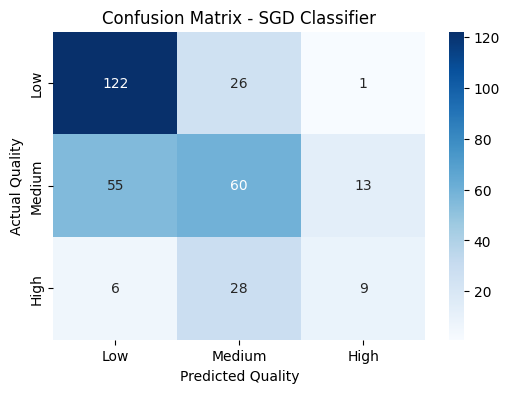

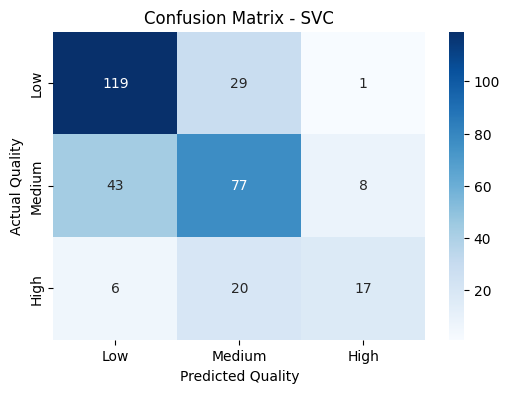

In [11]:
from sklearn.metrics import confusion_matrix

models = {
    "Random Forest": rf_predictions,
    "SGD Classifier": sgd_predictions,
    "SVC": svc_predictions
}

labels = ["Low", "Medium", "High"]

for name, predictions in models.items():
    cm = confusion_matrix(y_test, predictions, labels=labels)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=labels,
        yticklabels=labels
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Quality")
    plt.ylabel("Actual Quality")
    plt.show()

                 Feature  Importance
10               alcohol    0.150643
9              sulphates    0.114743
1       volatile acidity    0.110604
6   total sulfur dioxide    0.098726
7                density    0.090486
2            citric acid    0.079004
0          fixed acidity    0.073905
4              chlorides    0.073298
8                     pH    0.072261
3         residual sugar    0.069918
5    free sulfur dioxide    0.066413


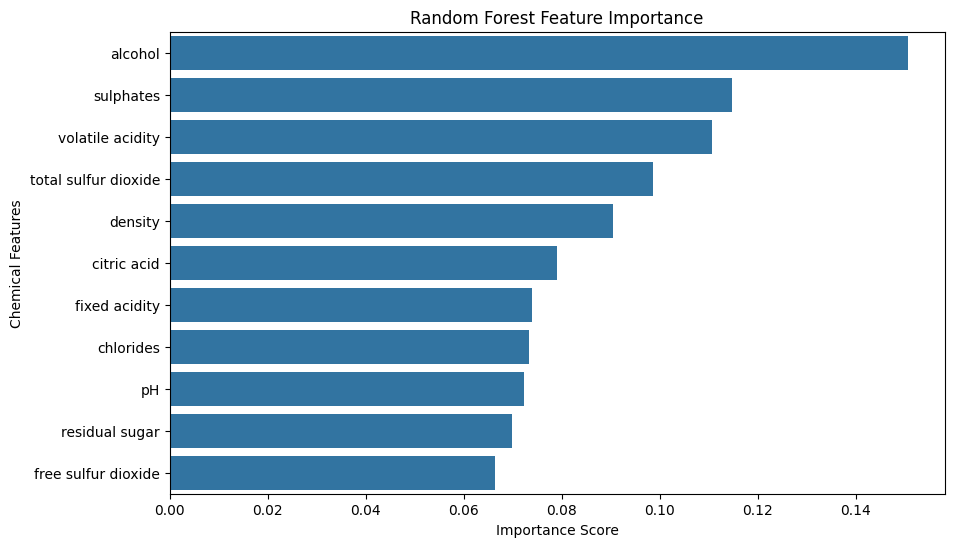

In [12]:
# Get feature importance from Random Forest
importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Chemical Features")
plt.show()

In [13]:
from sklearn.metrics import accuracy_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Random Forest", "SGD Classifier", "SVC"],
    "Accuracy": [
        accuracy_score(y_test, rf_predictions),
        accuracy_score(y_test, sgd_predictions),
        accuracy_score(y_test, svc_predictions)
    ],
    "Macro F1 Score": [
        f1_score(y_test, rf_predictions, average="macro"),
        f1_score(y_test, sgd_predictions, average="macro"),
        f1_score(y_test, svc_predictions, average="macro")
    ]
})

print("MODEL PERFORMANCE COMPARISON")
display(comparison.sort_values(by="Accuracy", ascending=False))

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro F1 Score
0,Random Forest,0.753125,0.723331
2,SVC,0.665625,0.616614
1,SGD Classifier,0.596875,0.501178


In [14]:
# Find the best model based on macro F1 score
best_model = comparison.loc[
    comparison["Macro F1 Score"].idxmax()
]

print("FINAL CONCLUSION")
print("-------------------------")
print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"] * 100, 2), "%")
print("Macro F1 Score:", round(best_model["Macro F1 Score"], 3))

print("\nThe best model is selected based on its macro F1 score.")
print("Macro F1 considers the performance across all quality categories.")

FINAL CONCLUSION
-------------------------
Best Model: Random Forest
Accuracy: 75.31 %
Macro F1 Score: 0.723

The best model is selected based on its macro F1 score.
Macro F1 considers the performance across all quality categories.
